# Phase 1 — RetinaFace Detection Audit

**Scope:** detector-stage audit
**Phase 0 baseline commit:** `f072db1`
**Status:** Analysis in progress

## Objective

Audit the detection and alignment stage of the completed
LFW, UTKFace and FairFace preprocessing pipeline.

The audit uses existing Phase 0 results. RetinaFace is not
rerun, and the frozen master table is not modified.

### Dataset-specific processing

- LFW: original unaligned images, processed with project RetinaFace.
- UTKFace: in-the-wild images, processed with project RetinaFace.
- FairFace: publisher-preprocessed dlib face chips; no project RetinaFace inference.

FairFace is retained in pipeline accounting but excluded
from project detector failure-rate calculations.

### Planned deliverables

- Complete detection-outcome reconciliation.
- Detection failures by eligible subgroup.
- Confidence distributions among detected faces.
- Landmark and alignment outcomes.
- Representative failure examples and limitations.

The descriptive confidence intervals in this notebook are
exploratory. Formal inferential tests and minimum-cell rules
must follow the approved Phase 1 statistical protocol.

In [1]:
from __future__ import annotations

import hashlib
import json
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from PIL import Image, ImageDraw, ImageOps

# Locate the project root.
current = Path.cwd().resolve()

candidates = [current, *current.parents]

ROOT = next(
    (
        directory
        for directory in candidates
        if (
            directory
            / "metadata"
            / "master_annotations.parquet"
        ).is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Start Jupyter from the project directory."
    )

sys.path.insert(0, str(ROOT))

from src import paths
from src.detection_integrity import (
    DetectionAuditInputs,
    prepare_detection_frame,
    build_detection_integrity_table,
    build_terminal_state_table,
    build_subgroup_failure_rows,
    build_confidence_rows,
    build_alignment_failure_rows,
    build_provenance_notes,
)

from run_phase0_validation import table_content_hash

METADATA = ROOT / "metadata"
# Uses the project's actual output convention (src/paths.py),
# the same tree run_detection_integrity.py already writes to.
OUTPUT = paths.DATA_PREP_OUTPUTS_DIR / "detection_integrity"
FIGURES = OUTPUT / "figures"

OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.grid": False,
    "font.size": 10,
})

SEED = 26041
DETECTION_THRESHOLD = 0.90

print("Project:", ROOT)
print("Output directory:", OUTPUT)
print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)

Project: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision
Output directory: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\detection_integrity
Python: 3.11.9
Pandas: 3.0.6


In [2]:
MASTER_PATH = METADATA / "master_annotations.parquet"
MANIFEST_PATH = METADATA / "file_manifest.parquet"

DIAGNOSTICS_PATH = (
    METADATA / "detection_alignment_diagnostics.parquet"
)

REFERENCE_PATH = METADATA / "phase0_reference_hashes.json"
QA_PATH = METADATA / "alignment_qa_review.csv"

required_files = [
    MASTER_PATH,
    MANIFEST_PATH,
    DIAGNOSTICS_PATH,
    REFERENCE_PATH,
    QA_PATH,
]

for path in required_files:
    if not path.is_file():
        raise FileNotFoundError(path)

reference = json.loads(
    REFERENCE_PATH.read_text(encoding="utf-8")
)

# The frozen reference is a mapping of artifact names to
# normalized content hashes.
reference_hashes = reference.get("hashes", reference)

expected_master_hash = reference_hashes.get(
    "master_annotations.parquet"
)

if not expected_master_hash:
    raise RuntimeError(
        "Could not locate the frozen master content hash "
        "in phase0_reference_hashes.json."
    )

actual_master_hash = table_content_hash(MASTER_PATH)

assert actual_master_hash == expected_master_hash, (
    "The current master differs from the frozen "
    "Phase 0 reference. Stop the audit."
)

master = pd.read_parquet(MASTER_PATH)
manifest = pd.read_parquet(MANIFEST_PATH)
diagnostics = pd.read_parquet(DIAGNOSTICS_PATH)
qa = pd.read_csv(QA_PATH)

assert len(master) == 135039
assert len(diagnostics) == 135039
assert master["image_id"].is_unique
assert diagnostics["image_id"].is_unique

assert len(qa) == 60
assert qa["qa_status"].eq("pass").all()

print("PHASE 0 INPUT VERIFICATION: PASS")
print("Master content hash:", actual_master_hash)
print("Canonical images:", len(master))
print("Extraction diagnostic rows:", len(diagnostics))
print("Production visual QA:", len(qa), "passed")

PHASE 0 INPUT VERIFICATION: PASS
Master content hash: 1a74efab81ac20a66f9aa75a2d005aa051286ba2116e5f22638a76e5968128ed
Canonical images: 135039
Extraction diagnostic rows: 135039
Production visual QA: 60 passed


## Detection integrity

This establishes the exact population reaching each
stage of the detection and alignment pipeline.

Every canonical image must have an accounted-for outcome.

A zero-detection result is different from an inference error.
A publisher-preprocessed FairFace image is neither a project
detection success nor a project detection failure.

We first reproduce the frozen Phase 0 counts, then visualize
the processing outcomes.

In [3]:
inputs = DetectionAuditInputs(
    master=master,
    manifest=manifest,
    diagnostics=diagnostics,
)

frame = prepare_detection_frame(inputs)

integrity_table = build_detection_integrity_table(frame)
terminal = build_terminal_state_table(frame)
provenance = build_provenance_notes(frame)

expected_datasets = {
    "fairface": 97698,
    "lfw": 13233,
    "utkface": 24108,
}

actual_datasets = dict(
    zip(
        integrity_table["dataset"],
        integrity_table["canonical_images"],
    )
)

assert actual_datasets == expected_datasets

expected_totals = {
    "canonical_images": 135039,
    "corrupt_not_processed": 15,
    "entered_detector": 37326,
    "inference_error": 0,
    "zero_detection": 39,
    "aligned_success": 37287,
    "publisher_preprocessed_not_project_detected": 97698,
}

for column, expected in expected_totals.items():
    observed = int(integrity_table[column].sum())

    assert observed == expected, (
        f"{column}: expected {expected}, got {observed}"
    )

assert len(frame) == 135039

assert not frame[
    "detector_terminal_state"
].eq("unclassified").any()

assert (
    frame["alignment_valid"].eq(True).sum()
    == 134985
)

print("Detection integrity: PASS")
display(integrity_table)
display(terminal)

Detection integrity: PASS


,dataset,canonical_images,source_preprocessed,project_detection_required,corrupt_not_processed,entered_detector,inference_success,inference_error,detected_ge1,zero_detection,multi_detection,primary_selection_failure,landmark_failure,alignment_attempted,alignment_failure,aligned_success,publisher_preprocessed_not_project_detected,detector_reconciles
0,fairface,97698,97698,0,0,0,0,0,0,0,0,0,0,0,0,0,97698,True
1,lfw,13233,0,13233,0,13233,13233,0,13233,0,1922,0,0,13233,0,13233,0,True
2,utkface,24108,0,24108,15,24093,24093,0,24054,39,893,0,0,24054,0,24054,0,True


,dataset,detector_terminal_state,n
0,fairface,publisher_preprocessed_not_project_detected,97698
1,lfw,aligned_success,13233
2,utkface,aligned_success,24054
3,utkface,corrupt_not_processed,15
4,utkface,zero_detection,39


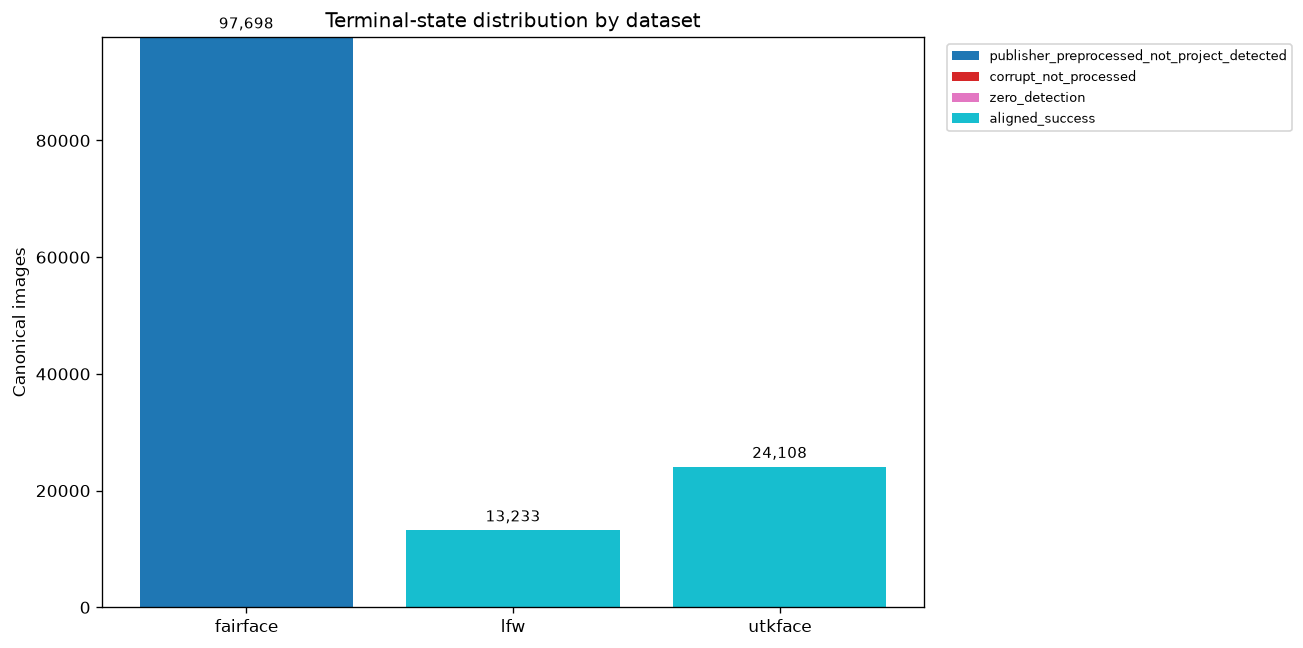

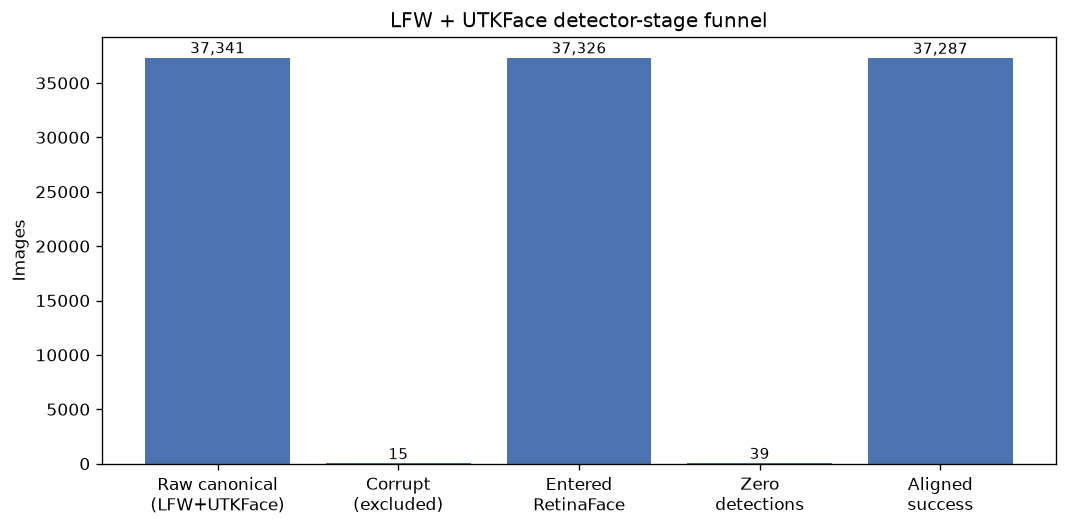

In [4]:
counts = {
    column: int(integrity_table[column].sum())
    for column in expected_totals
}

# Terminal-state distribution per dataset, straight from the
# reconciled table -- no manually placed numbers or shapes.
state_order = [
    "publisher_preprocessed_not_project_detected",
    "corrupt_not_processed",
    "inference_error",
    "zero_detection",
    "primary_selection_failure",
    "landmark_failure",
    "alignment_failure",
    "aligned_success",
    "detected_no_project_alignment",
]

pivot = (
    terminal
    .pivot(index="dataset", columns="detector_terminal_state", values="n")
    .reindex(columns=[s for s in state_order if s in terminal["detector_terminal_state"].unique()])
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(11, 5.5))

bottom = np.zeros(len(pivot))
colours = plt.cm.tab10(np.linspace(0, 1, len(pivot.columns)))

for colour, state in zip(colours, pivot.columns):
    values = pivot[state].to_numpy()
    ax.bar(pivot.index, values, bottom=bottom, label=state, color=colour)
    bottom += values

ax.set_ylabel("Canonical images")
ax.set_title("Terminal-state distribution by dataset")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

for i, dataset in enumerate(pivot.index):
    ax.text(i, pivot.loc[dataset].sum() + 1500, f"{int(pivot.loc[dataset].sum()):,}", ha="center", fontsize=9)

fig.tight_layout()

fig.savefig(
    FIGURES / "detection_terminal_state_distribution.png",
    bbox_inches="tight",
)

fig.savefig(
    FIGURES / "detection_terminal_state_distribution.pdf",
    bbox_inches="tight",
)

plt.show()

# Detector-stage funnel for LFW and UTKFace only (FairFace never
# entered project RetinaFace, so it is excluded from this view).
funnel_labels = [
    "Raw canonical\n(LFW+UTKFace)",
    "Corrupt\n(excluded)",
    "Entered\nRetinaFace",
    "Zero\ndetections",
    "Aligned\nsuccess",
]

funnel_values = [
    counts["entered_detector"] + counts["corrupt_not_processed"],
    counts["corrupt_not_processed"],
    counts["entered_detector"],
    counts["zero_detection"],
    counts["aligned_success"],
]

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(funnel_labels))
bars = ax.bar(x, funnel_values, color="#4C72B0")

ax.set_xticks(x, funnel_labels)
ax.set_ylabel("Images")
ax.set_title("LFW + UTKFace detector-stage funnel")

for bar, value in zip(bars, funnel_values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 400, f"{value:,}", ha="center", fontsize=9)

fig.tight_layout()

fig.savefig(
    FIGURES / "detector_stage_funnel.png",
    bbox_inches="tight",
)

fig.savefig(
    FIGURES / "detector_stage_funnel.pdf",
    bbox_inches="tight",
)

plt.show()

## Detection failures by subgroup

We now examine detection failures among images that
actually entered project RetinaFace.

The failure definition is:

- Detector inference error, or
- Successful inference with zero detections.

**Scope note: these findings describe UTKFace only.**
In this master table, LFW has no usable native or derived
gender, age-band, or race labels under the eligibility rule
applied here (native labels or a derived label at or above
the confidence threshold). All 39 detector failures are also
UTKFace images; LFW and FairFace contributed zero. Nothing
below should be read as a statement about LFW or FairFace
subgroup detection performance.

**Small-sample caution.** There are only 39 failure events
in total, spread across three demographic axes and several
categories each. Per-subgroup counts are small, several are
in the single digits, and the resulting rates and intervals
are wide and unstable. These are descriptive signals for
follow-up, not a basis for concluding one subgroup performs
differently from another.

Subgroup analyses retain dataset-specific labels.
Native race labels are not pooled across datasets.

Wilson 95% intervals are shown descriptively to indicate
sampling uncertainty. They are not a substitute for the
project's approved statistical-testing and
multiple-comparison procedures.

A low failure count is not evidence of equivalent detector
performance across subgroups.

In [5]:
subgroup_failures = build_subgroup_failure_rows(frame)

# Wilson score interval for a binomial proportion.
# Exploratory descriptive interval, not a formal
# multiple-comparison-adjusted inference procedure.

def wilson_interval(successes, n, z=1.959963984540054):
    if n <= 0:
        return np.nan, np.nan

    p = successes / n
    z2 = z ** 2

    denominator = 1 + z2 / n

    centre = (
        p + z2 / (2 * n)
    ) / denominator

    half_width = (
        z
        * np.sqrt(
            p * (1 - p) / n
            + z2 / (4 * n ** 2)
        )
        / denominator
    )

    return centre - half_width, centre + half_width


if len(subgroup_failures):
    intervals = subgroup_failures.apply(
        lambda row: wilson_interval(
            row["detection_failures"],
            row["n"],
        ),
        axis=1,
    )

    subgroup_failures["ci95_lower"] = [
        result[0] for result in intervals
    ]

    subgroup_failures["ci95_upper"] = [
        result[1] for result in intervals
    ]

    subgroup_failures = subgroup_failures.sort_values(
        ["dataset", "axis", "subgroup"],
        ignore_index=True,
    )


# Report how many images have usable labels.
eligible = frame.loc[
    frame["entered_detector"]
].copy()

coverage_rows = []

for dataset, group in eligible.groupby("dataset"):
    for axis in ["gender", "age_band", "race"]:
        values = group[axis].astype("string")

        known = (
            values.notna()
            & ~values.str.lower().isin(
                ["unknown", "none", "nan", ""]
            )
        )

        if axis == "race":
            known &= (
                group["race_source"]
                .astype("string")
                .str.lower()
                .eq("native")
            )

        coverage_rows.append({
            "dataset": dataset,
            "axis": axis,
            "entered_detector": len(group),
            "usable_labels": int(known.sum()),
            "unavailable_or_ineligible": int(
                (~known).sum()
            ),
        })

label_coverage = pd.DataFrame(coverage_rows)

print("Subgroup failure table")
display(subgroup_failures)

print("Subgroup label coverage")
display(label_coverage)

Subgroup failure table


,dataset,axis,subgroup,n,detection_failures,inference_errors,zero_detections,detection_failure_rate,race_native_only,ci95_lower,ci95_upper
0,utkface,age_band,0-19,4885,28,0,28,0.005732,False,3.968728e-03,0.008272
1,utkface,age_band,20-39,11909,3,0,3,0.000252,False,8.567586e-05,0.000740
2,utkface,age_band,40-59,4552,0,0,0,0.000000,False,5.421011e-20,0.000843
3,utkface,age_band,60+,2743,8,0,8,0.002917,False,1.478586e-03,0.005745
4,utkface,gender,female,11515,22,0,22,0.001911,False,1.262087e-03,0.002891
5,utkface,gender,male,12574,17,0,17,0.001352,False,8.443248e-04,0.002164
6,utkface,race,Asian,3586,17,0,17,0.004741,True,2.962004e-03,0.007579
7,utkface,race,Black,4558,6,0,6,0.001316,True,6.034380e-04,0.002869
8,utkface,race,Indian,4027,3,0,3,0.000745,True,2.533891e-04,0.002188
9,utkface,race,Others,1711,1,0,1,0.000584,True,1.031779e-04,0.003303


Subgroup label coverage


,dataset,axis,entered_detector,usable_labels,unavailable_or_ineligible
0,lfw,gender,13233,0,13233
1,lfw,age_band,13233,0,13233
2,lfw,race,13233,0,13233
3,utkface,gender,24093,24089,4
4,utkface,age_band,24093,24089,4
5,utkface,race,24093,24089,4


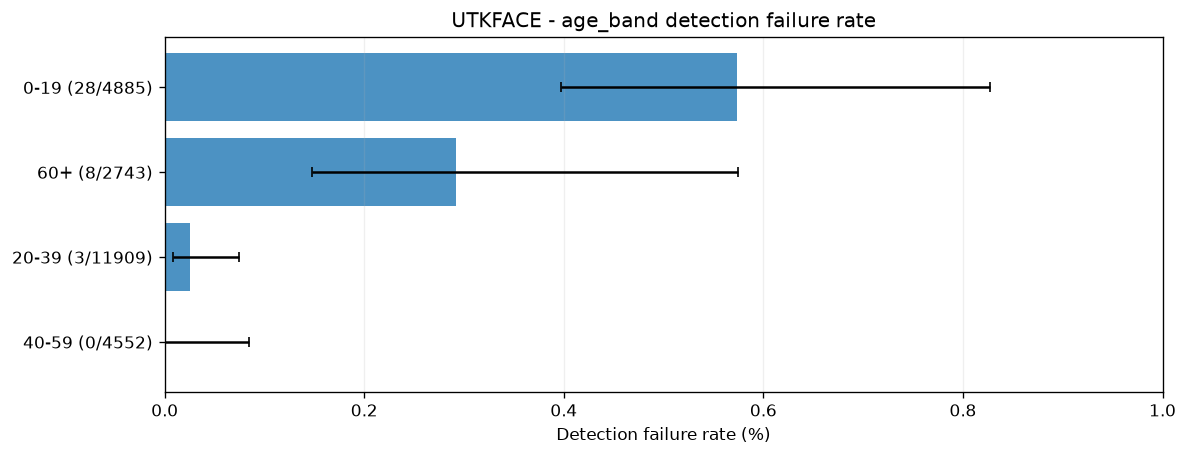

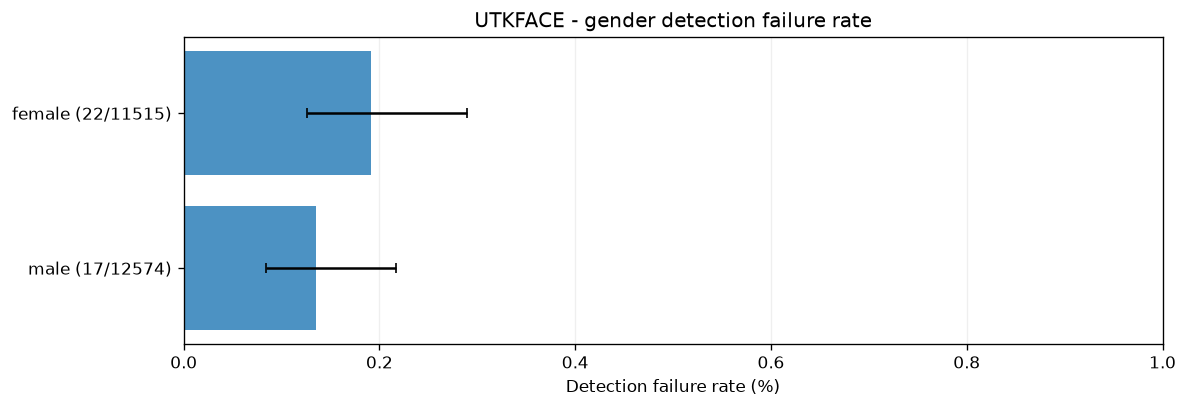

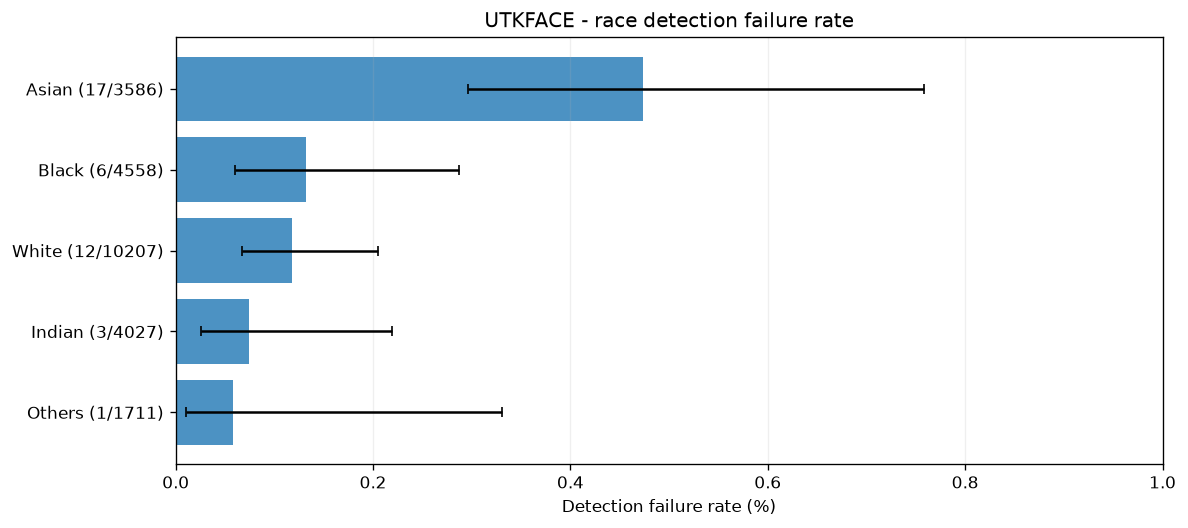

In [6]:
if subgroup_failures.empty:
    print("No eligible subgroup rows.")
else:
    for (dataset, axis), subset in subgroup_failures.groupby(
        ["dataset", "axis"],
        sort=True,
    ):
        subset = subset.sort_values(
            "detection_failure_rate",
            ascending=True,
        ).reset_index(drop=True)

        y = np.arange(len(subset))

        fig, ax = plt.subplots(
            figsize=(
                10,
                max(3.5, 0.6 * len(subset) + 1.5),
            )
        )

        rates = subset[
            "detection_failure_rate"
        ].to_numpy(dtype=float)

        lower = subset[
            "ci95_lower"
        ].to_numpy(dtype=float)

        upper = subset[
            "ci95_upper"
        ].to_numpy(dtype=float)

        ax.barh(y, rates * 100, alpha=0.8)

        # Wilson intervals are centred on a slightly different
        # point than the raw rate for very small n, which can make
        # (rate - lower) negative by a tiny floating-point margin.
        # Clip to zero rather than let errorbar() reject it.
        xerr_lower = np.clip((rates - lower) * 100, 0, None)
        xerr_upper = np.clip((upper - rates) * 100, 0, None)

        ax.errorbar(
            rates * 100,
            y,
            xerr=[xerr_lower, xerr_upper],
            fmt="none",
            ecolor="black",
            capsize=3,
        )

        labels = [
            (
                f"{row.subgroup} "
                f"({row.detection_failures}/{row.n})"
            )
            for row in subset.itertuples(index=False)
        ]

        ax.set_yticks(y, labels)
        ax.set_xlabel("Detection failure rate (%)")

        ax.set_title(
            f"{dataset.upper()} - {axis} detection failure rate"
        )

        ax.set_xlim(
            0,
            max(
                1.0,
                min(100.0, float(np.nanmax(upper)) * 115),
            ),
        )

        ax.grid(axis="x", alpha=0.2)

        fig.tight_layout()

        filename = (
            f"{dataset}_{axis}_failure_rates"
        )

        fig.savefig(
            FIGURES / f"{filename}.png",
            bbox_inches="tight",
        )

        fig.savefig(
            FIGURES / f"{filename}.pdf",
            bbox_inches="tight",
        )

        plt.show()

## Detection-confidence distributions

Detection confidence is available only when a primary
face was successfully detected.

Zero-detection images do not have a primary-face confidence.
They must not be assigned a confidence of zero.

All results are conditioned on the frozen RetinaFace
confidence threshold of 0.90.

These are detector scores, not calibrated probabilities
that a detection is correct.

We inspect the overall distributions and available
within-dataset subgroup distributions.

Confidence summaries


,dataset,axis,subgroup,n,mean,std,median,q1,q3,minimum,maximum,race_native_only
0,utkface,gender,female,11493,0.998553,0.005430,0.999652,0.998855,0.999881,0.901225,0.999998,False
1,utkface,gender,male,12557,0.998688,0.004969,0.999702,0.998927,0.999896,0.900774,0.999999,False
2,utkface,age_band,0-19,4857,0.997696,0.007402,0.999539,0.998364,0.999879,0.902859,0.999999,False
3,utkface,age_band,20-39,11906,0.998925,0.004275,0.999714,0.999026,0.999897,0.900774,0.999999,False
4,utkface,age_band,40-59,4552,0.999119,0.002438,0.999717,0.999070,0.999895,0.927931,0.999998,False
5,utkface,age_band,60+,2735,0.998135,0.006929,0.999582,0.998614,0.999853,0.901704,0.999998,False
6,utkface,race,Asian,3569,0.998034,0.006387,0.999542,0.998476,0.999850,0.900774,0.999999,True
7,utkface,race,Black,4552,0.998634,0.005806,0.999695,0.998954,0.999896,0.902071,0.999999,True
8,utkface,race,Indian,4024,0.998842,0.003644,0.999651,0.998853,0.999887,0.902859,0.999996,True
9,utkface,race,Others,1710,0.999039,0.002325,0.999708,0.999028,0.999903,0.946265,0.999999,True


Primary detections with confidence: 37287


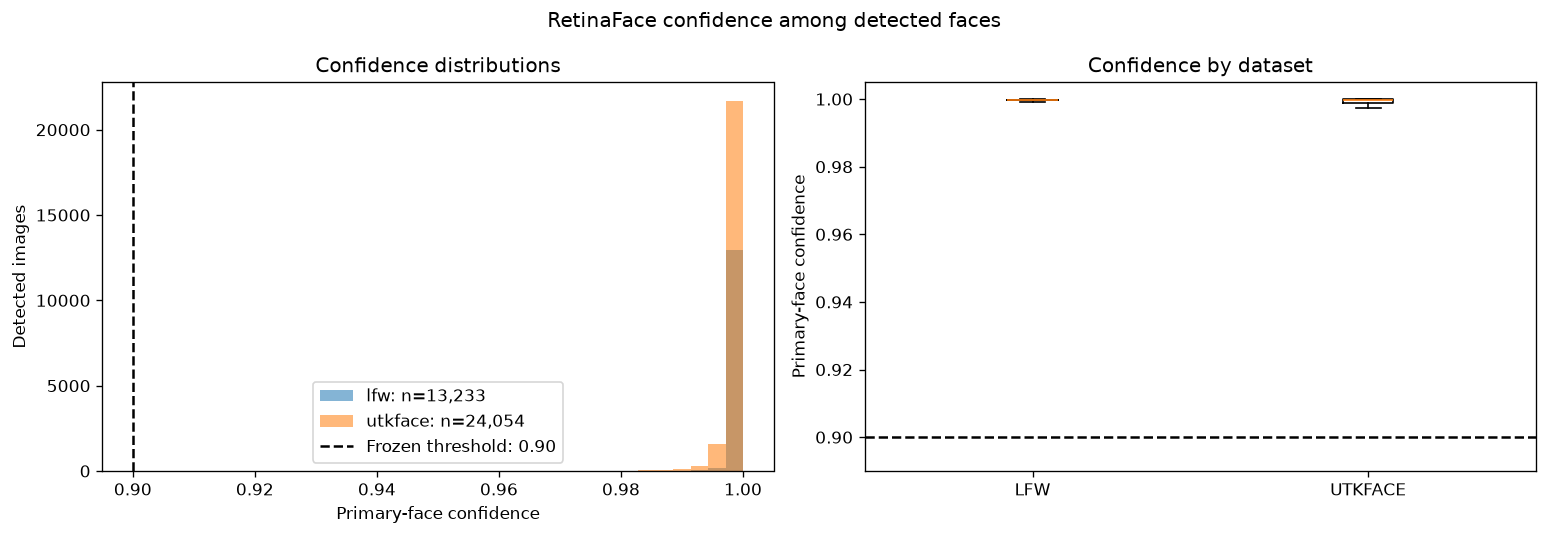

In [7]:
confidence_summary, confidence_values = (
    build_confidence_rows(frame)
)

assert len(confidence_values) == int(
    integrity_table["detected_ge1"].sum()
    - integrity_table["primary_selection_failure"].sum()
)

assert confidence_values[
    "det_confidence"
].notna().all()

assert (
    confidence_values["det_confidence"].min()
    >= DETECTION_THRESHOLD - 1e-6
)

print("Confidence summaries")
display(confidence_summary)

print(
    "Primary detections with confidence:",
    len(confidence_values),
)

# Overall distribution by source dataset.
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)

confidence_groups = []

for dataset, group in confidence_values.groupby("dataset"):
    scores = group[
        "det_confidence"
    ].astype(float).to_numpy()

    axes[0].hist(
        scores,
        bins=np.linspace(0.90, 1.0, 36),
        alpha=0.55,
        label=f"{dataset}: n={len(scores):,}",
    )

    confidence_groups.append(
        (dataset, scores)
    )

axes[0].axvline(
    DETECTION_THRESHOLD,
    linestyle="--",
    color="black",
    label="Frozen threshold: 0.90",
)

axes[0].set_xlabel("Primary-face confidence")
axes[0].set_ylabel("Detected images")
axes[0].set_title("Confidence distributions")
axes[0].legend()

if confidence_groups:
    axes[1].boxplot(
        [values for _, values in confidence_groups],
        tick_labels=[
            name.upper()
            for name, _ in confidence_groups
        ],
        showfliers=False,
    )

axes[1].axhline(
    DETECTION_THRESHOLD,
    linestyle="--",
    color="black",
)

axes[1].set_ylabel("Primary-face confidence")
axes[1].set_title("Confidence by dataset")
axes[1].set_ylim(0.89, 1.005)

fig.suptitle(
    "RetinaFace confidence among detected faces"
)

fig.tight_layout()

fig.savefig(
    FIGURES / "confidence_distributions.png",
    bbox_inches="tight",
)

fig.savefig(
    FIGURES / "confidence_distributions.pdf",
    bbox_inches="tight",
)

plt.show()

### GOV-003 reporting rules and multi-group test diagnostics

Before any subgroup rate or confidence summary is treated as
reportable, the frozen GOV-003 image-level reporting rules
(minimum cell size, low-confidence sample-size flag) are
applied to `subgroup_failures` and `confidence_summary`.

We then diagnose -- but do not yet interpret -- the frozen
multi-group chi-square tests specified in
`configs/statistics.yaml` for the subgroup age and race axes,
since there are only 39 total failures and some contingency
cells may be too small for the usual chi-square
approximation to be reliable.

In [8]:
# Apply the frozen GOV-003 image-level reporting rules.

def add_reporting_flags(table, n_column="n"):
    result = table.copy()

    result["thin_cell"] = result[n_column] < 30

    result["low_confidence"] = (
        (result[n_column] >= 30)
        & (result[n_column] < 100)
    )

    return result


subgroup_failures = add_reporting_flags(subgroup_failures)
confidence_summary = add_reporting_flags(confidence_summary)

print("Subgroup-failure reporting flags:")
display(
    subgroup_failures[
        [
            "dataset",
            "axis",
            "subgroup",
            "n",
            "detection_failures",
            "thin_cell",
            "low_confidence",
        ]
    ]
)

print("Confidence-summary reporting flags:")
display(
    confidence_summary[
        [
            "dataset",
            "axis",
            "subgroup",
            "n",
            "thin_cell",
            "low_confidence",
        ]
    ]
)

assert not subgroup_failures["thin_cell"].any()
assert not subgroup_failures["low_confidence"].any()

print("GOV-003 single-axis reporting checks: PASS")

Subgroup-failure reporting flags:


,dataset,axis,subgroup,n,detection_failures,thin_cell,low_confidence
0,utkface,age_band,0-19,4885,28,False,False
1,utkface,age_band,20-39,11909,3,False,False
2,utkface,age_band,40-59,4552,0,False,False
3,utkface,age_band,60+,2743,8,False,False
4,utkface,gender,female,11515,22,False,False
5,utkface,gender,male,12574,17,False,False
6,utkface,race,Asian,3586,17,False,False
7,utkface,race,Black,4558,6,False,False
8,utkface,race,Indian,4027,3,False,False
9,utkface,race,Others,1711,1,False,False


Confidence-summary reporting flags:


,dataset,axis,subgroup,n,thin_cell,low_confidence
0,utkface,gender,female,11493,False,False
1,utkface,gender,male,12557,False,False
2,utkface,age_band,0-19,4857,False,False
3,utkface,age_band,20-39,11906,False,False
4,utkface,age_band,40-59,4552,False,False
5,utkface,age_band,60+,2735,False,False
6,utkface,race,Asian,3569,False,False
7,utkface,race,Black,4552,False,False
8,utkface,race,Indian,4024,False,False
9,utkface,race,Others,1710,False,False


GOV-003 single-axis reporting checks: PASS


In [9]:
from scipy.stats import chi2_contingency

# Diagnose the frozen multi-group chi-square tests.
# Do not interpret p-values yet.

chi_square_rows = []

for axis in ["age_band", "race"]:
    subset = subgroup_failures.loc[
        (subgroup_failures["dataset"] == "utkface")
        & (subgroup_failures["axis"] == axis)
    ].sort_values("subgroup")

    failures = subset[
        "detection_failures"
    ].to_numpy(dtype=int)

    successes = (
        subset["n"] - subset["detection_failures"]
    ).to_numpy(dtype=int)

    contingency = np.column_stack(
        [failures, successes]
    )

    _, _, _, expected = chi2_contingency(
        contingency
    )

    print(f"\n{axis.upper()}")
    print("Groups:", subset["subgroup"].tolist())
    print("Observed failures:", failures.tolist())
    print(
        "Expected failure counts:",
        expected[:, 0].round(3).tolist()
    )
    print(
        "Minimum expected count:",
        round(float(expected.min()), 3)
    )
    print(
        "Any expected count below 5:",
        bool((expected < 5).any())
    )

    chi_square_rows.append({
        "axis": axis,
        "groups": ", ".join(subset["subgroup"].tolist()),
        "observed_failures": ", ".join(str(v) for v in failures.tolist()),
        "expected_failure_counts": ", ".join(str(v) for v in expected[:, 0].round(3).tolist()),
        "minimum_expected_count": round(float(expected.min()), 3),
        "any_expected_below_5": bool((expected < 5).any()),
    })

chi_square_diagnostics = pd.DataFrame(chi_square_rows)

chi_square_diagnostics.to_csv(
    OUTPUT / "chi_square_diagnostics.csv",
    index=False,
)

print()
print("Saved:", OUTPUT / "chi_square_diagnostics.csv")


AGE_BAND
Groups: ['0-19', '20-39', '40-59', '60+']
Observed failures: [28, 3, 0, 8]
Expected failure counts: [7.909, 19.281, 7.37, 4.441]
Minimum expected count: 4.441
Any expected count below 5: True

RACE
Groups: ['Asian', 'Black', 'Indian', 'Others', 'White']
Observed failures: [17, 6, 3, 1, 12]
Expected failure counts: [5.806, 7.379, 6.52, 2.77, 16.525]
Minimum expected count: 2.77
Any expected count below 5: True

Saved: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\detection_integrity\chi_square_diagnostics.csv


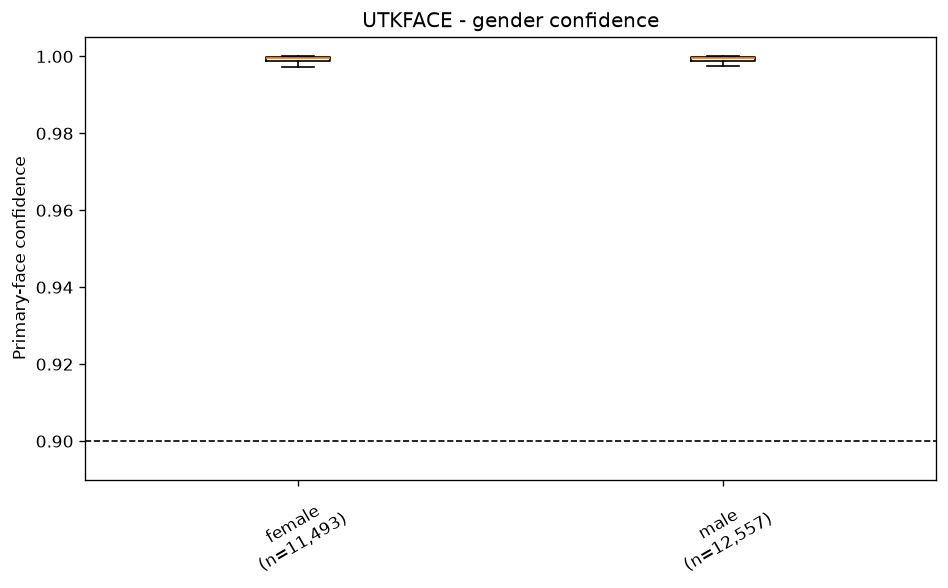

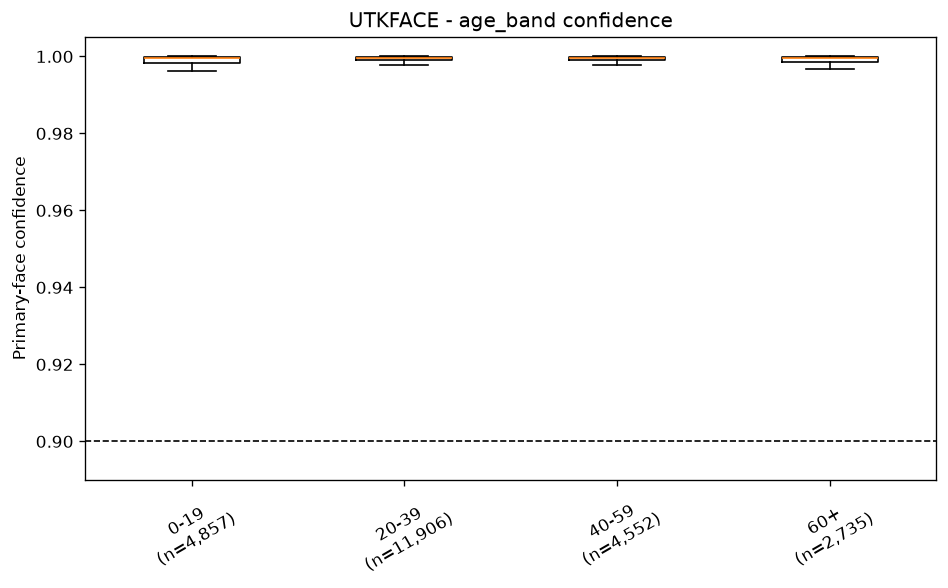

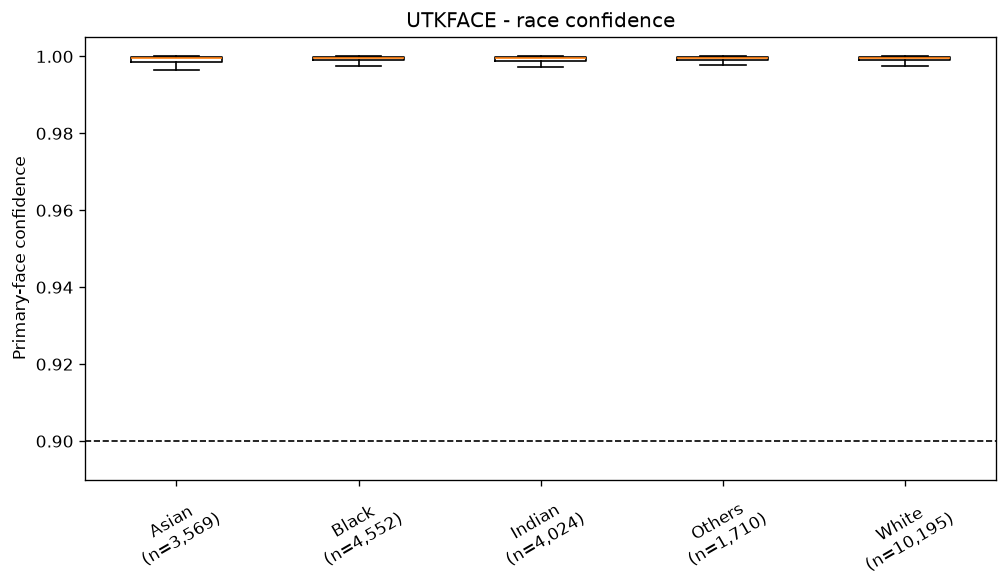

In [10]:
detected_with_confidence = frame.loc[
    frame["detected"]
    & frame["primary_selected"]
].copy()

for dataset, dataset_frame in (
    detected_with_confidence.groupby("dataset")
):
    for axis in ["gender", "age_band", "race"]:
        source = dataset_frame.copy()

        source[axis] = source[axis].astype("string")

        valid = (
            source[axis].notna()
            & ~source[axis].str.lower().isin(
                ["unknown", "none", "nan", ""]
            )
        )

        if axis == "race":
            valid &= (
                source["race_source"]
                .astype("string")
                .str.lower()
                .eq("native")
            )

        source = source.loc[valid]

        if source.empty:
            continue

        grouped = list(source.groupby(axis))

        if not grouped:
            continue

        values = [
            pd.to_numeric(
                group["det_confidence"],
                errors="coerce",
            ).dropna().to_numpy()
            for _, group in grouped
        ]

        labels = [
            f"{name}\n(n={len(group):,})"
            for name, group in grouped
        ]

        fig, ax = plt.subplots(
            figsize=(
                max(8, 1.3 * len(labels) + 2),
                5,
            )
        )

        ax.boxplot(
            values,
            tick_labels=labels,
            showfliers=False,
        )

        ax.axhline(
            DETECTION_THRESHOLD,
            color="black",
            linestyle="--",
            linewidth=1,
        )

        ax.set_ylabel("Primary-face confidence")
        ax.set_ylim(0.89, 1.005)

        ax.set_title(
            f"{dataset.upper()} - {axis} confidence"
        )

        ax.tick_params(
            axis="x",
            labelrotation=30,
        )

        fig.tight_layout()

        filename = (
            f"{dataset}_{axis}_confidence"
        )

        fig.savefig(
            FIGURES / f"{filename}.png",
            bbox_inches="tight",
        )

        fig.savefig(
            FIGURES / f"{filename}.pdf",
            bbox_inches="tight",
        )

        plt.show()

## Landmark and alignment outcomes

This section separates failures at distinct stages:

1. Successful inference but no detected face.
2. Detected face but failure to select a primary face.
3. Invalid or missing five-point landmarks.
4. Failure of the project alignment operation.
5. Successful project alignment.

Multiple detected faces are recorded separately and are
not automatically treated as failures.

FairFace's publisher alignment is excluded from project
landmark and alignment success rates.

We also verify that each successful project alignment
has a finite 2 x 3 transformation matrix.

In [11]:
alignment_failures = build_alignment_failure_rows(frame)

project = frame.loc[
    frame["project_detection_required"]
    & ~frame["corrupt"]
].copy()

successful = project.loc[
    project["aligned_success"]
].copy()


def transform_is_valid(value):
    try:
        if value is None:
            return False

        # Parquet/PyArrow deserializes a nested list column as a
        # 1-D object array of 1-D arrays, not a clean 2-D array.
        # np.asarray(value, dtype=float) rejects that shape under
        # NumPy 2.x ("setting an array element with a sequence"),
        # so stack explicitly instead.
        array = np.stack(value).astype(float)

        return (
            array.shape == (2, 3)
            and np.isfinite(array).all()
        )

    except (TypeError, ValueError):
        return False


successful["transform_valid"] = (
    successful["alignment_transform"]
    .map(transform_is_valid)
)

assert successful["transform_valid"].all()

assert len(successful) == 37287

assert int(
    project["zero_detection"].sum()
) == 39

assert int(
    project["detector_inference_error"].sum()
) == 0

alignment_counts = {
    "inference_error": int(
        project["detector_inference_error"].sum()
    ),
    "zero_detection": int(
        project["zero_detection"].sum()
    ),
    "primary_selection_failure": int(
        project["primary_selection_failure"].sum()
    ),
    "landmark_failure": int(
        project["landmark_failure"].sum()
    ),
    "alignment_failure": int(
        project["alignment_failure"].sum()
    ),
    "aligned_success": int(
        project["aligned_success"].sum()
    ),
}

alignment_table = pd.DataFrame(
    [
        {"outcome": name, "n": count}
        for name, count in alignment_counts.items()
    ]
)

assert sum(alignment_counts.values()) == 37326

print("Project alignment outcomes")
display(alignment_table)

print("Alignment subgroup analysis")
display(alignment_failures)

print(
    "Stored valid 2x3 transformations:",
    int(successful["transform_valid"].sum()),
)

Project alignment outcomes


,outcome,n
0,inference_error,0
1,zero_detection,39
2,primary_selection_failure,0
3,landmark_failure,0
4,alignment_failure,0
5,aligned_success,37287


Alignment subgroup analysis


,dataset,axis,subgroup,n_detected_primary,landmark_failures,alignment_failures,landmark_or_alignment_failures,landmark_failure_rate,alignment_failure_rate,combined_failure_rate,race_native_only
0,utkface,gender,female,11493,0,0,0,0.0,0.0,0.0,False
1,utkface,gender,male,12557,0,0,0,0.0,0.0,0.0,False
2,utkface,age_band,0-19,4857,0,0,0,0.0,0.0,0.0,False
3,utkface,age_band,20-39,11906,0,0,0,0.0,0.0,0.0,False
4,utkface,age_band,40-59,4552,0,0,0,0.0,0.0,0.0,False
5,utkface,age_band,60+,2735,0,0,0,0.0,0.0,0.0,False
6,utkface,race,Asian,3569,0,0,0,0.0,0.0,0.0,True
7,utkface,race,Black,4552,0,0,0,0.0,0.0,0.0,True
8,utkface,race,Indian,4024,0,0,0,0.0,0.0,0.0,True
9,utkface,race,Others,1710,0,0,0,0.0,0.0,0.0,True


Stored valid 2x3 transformations: 37287


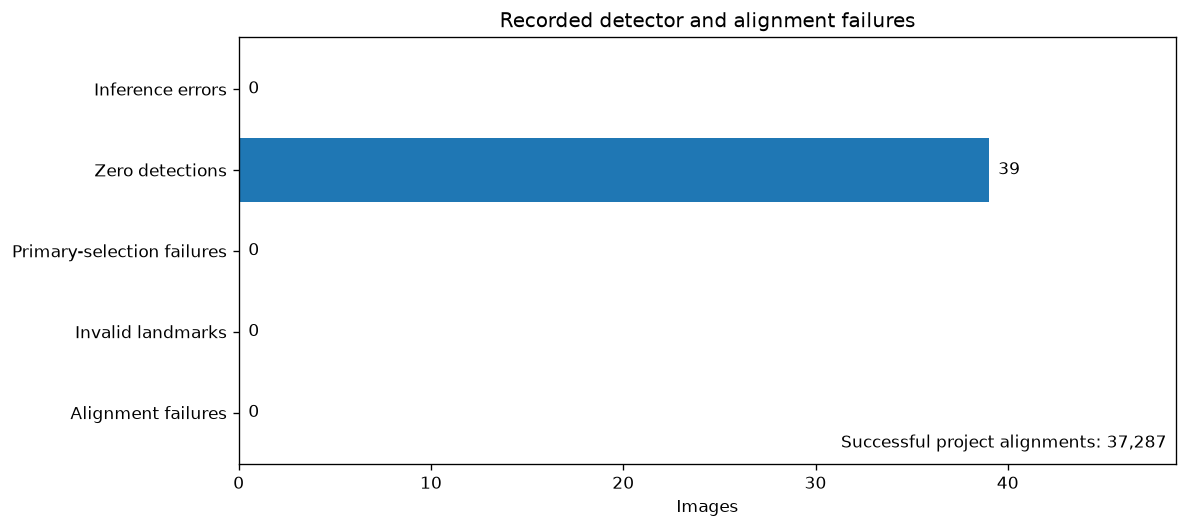

In [12]:
failure_names = [
    "Inference errors",
    "Zero detections",
    "Primary-selection failures",
    "Invalid landmarks",
    "Alignment failures",
]

failure_values = [
    alignment_counts["inference_error"],
    alignment_counts["zero_detection"],
    alignment_counts["primary_selection_failure"],
    alignment_counts["landmark_failure"],
    alignment_counts["alignment_failure"],
]

fig, ax = plt.subplots(figsize=(10, 4.5))

y = np.arange(len(failure_names))

bars = ax.barh(
    y,
    failure_values,
)

ax.set_yticks(y, failure_names)
ax.invert_yaxis()

ax.set_xlabel("Images")
ax.set_title(
    "Recorded detector and alignment failures"
)

ax.set_xlim(
    0,
    max(failure_values + [1]) * 1.25,
)

for bar, count in zip(bars, failure_values):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        str(count),
        va="center",
    )

ax.text(
    0.99,
    0.03,
    (
        f"Successful project alignments: "
        f"{alignment_counts['aligned_success']:,}"
    ),
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
)

fig.tight_layout()

fig.savefig(
    FIGURES / "alignment_outcomes.png",
    bbox_inches="tight",
)

fig.savefig(
    FIGURES / "alignment_outcomes.pdf",
    bbox_inches="tight",
)

plt.show()

## Failure-case review and limitations

This section combines the numerical findings with a
reproducible visual inspection of detector failures.

There are only 39 zero-detection cases in total, so the
contact sheet below shows all of them rather than a sample.
Each has been individually reviewed and assigned a
descriptive visual-review category in the table that
follows the contact sheet.

The review records what is visible, not why RetinaFace
failed. Image appearance alone cannot establish causation.
Likewise, successful detection does not establish that the
selected face or alignment is correct.

The generated contact sheet is an internal research
artifact. Publication of source images remains subject
to the applicable dataset licenses and project governance.

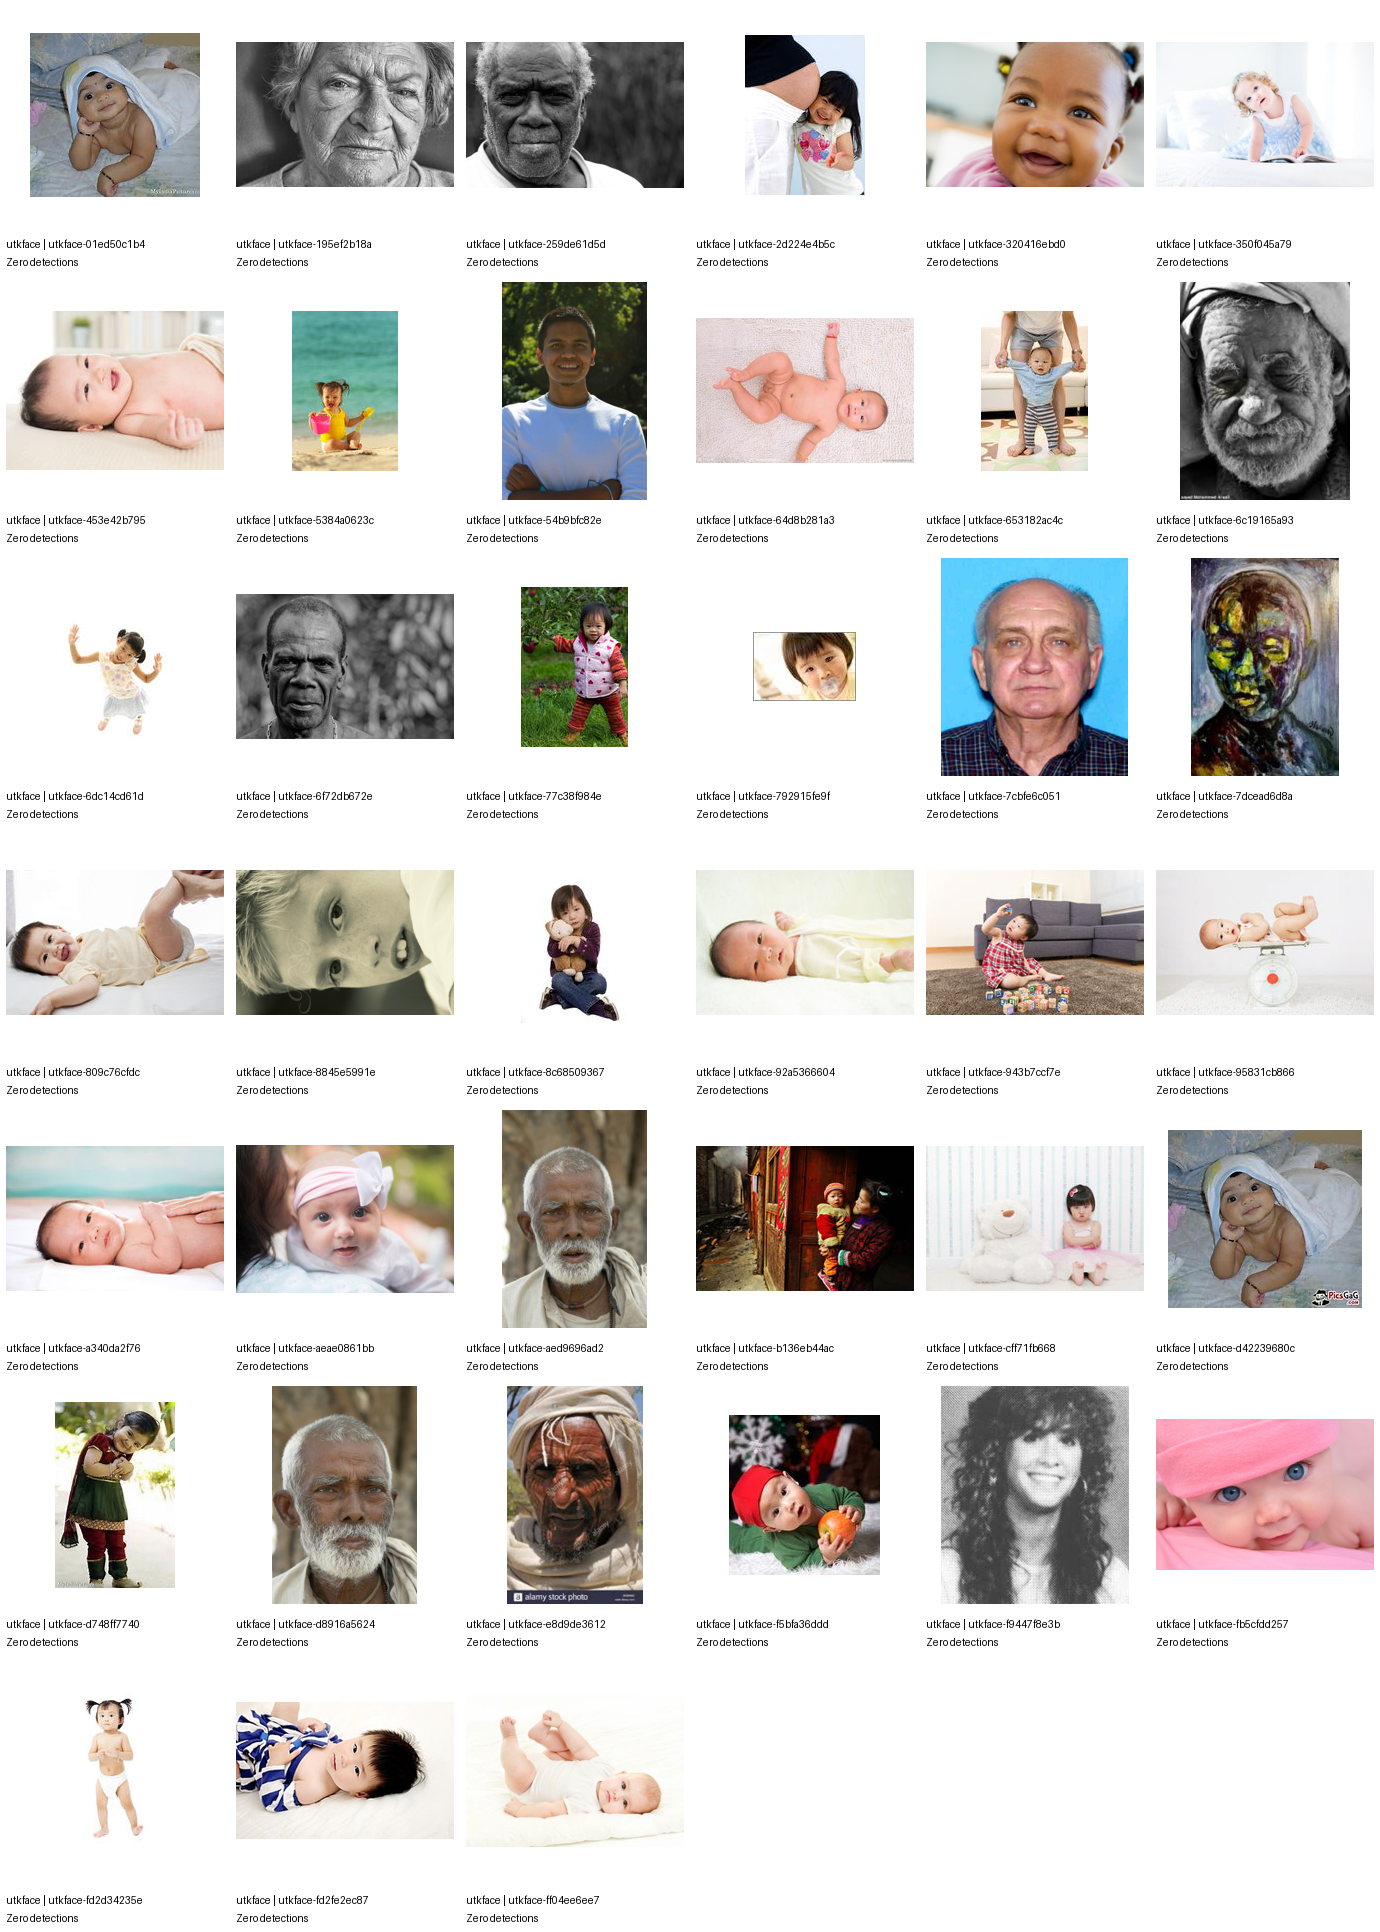

Reviewed: 39 of 39 zero-detection cases (full population)


In [13]:
failures = frame.loc[
    frame["zero_detection"]
].copy()

# Only 39 cases exist in total, so the full population is
# reviewed rather than a sample.
selected_failures = failures.copy()

selected_failures = selected_failures.sort_values(
    ["dataset", "image_id"],
    ignore_index=True,
)

THUMB_WIDTH = 230
THUMB_HEIGHT = 230
LABEL_HEIGHT = 46

COLUMNS = 6

ROWS = max(
    1,
    int(np.ceil(
        len(selected_failures) / COLUMNS
    )),
)

sheet = Image.new(
    "RGB",
    (
        COLUMNS * THUMB_WIDTH,
        ROWS * (THUMB_HEIGHT + LABEL_HEIGHT),
    ),
    "white",
)

draw = ImageDraw.Draw(sheet)

for position, row in enumerate(
    selected_failures.itertuples(index=False)
):
    column = position % COLUMNS
    row_index = position // COLUMNS

    left = column * THUMB_WIDTH

    top = (
        row_index
        * (THUMB_HEIGHT + LABEL_HEIGHT)
    )

    try:
        image_path = paths.data_abs(
            str(row.original_path)
        )

        with Image.open(image_path) as image:
            preview = ImageOps.exif_transpose(
                image
            ).convert("RGB")

        preview.thumbnail(
            (THUMB_WIDTH - 12, THUMB_HEIGHT - 12)
        )

        paste_x = (
            left
            + (THUMB_WIDTH - preview.width) // 2
        )

        paste_y = (
            top
            + (THUMB_HEIGHT - preview.height) // 2
        )

        sheet.paste(
            preview,
            (paste_x, paste_y),
        )

    except Exception as exc:
        draw.text(
            (left + 12, top + 30),
            "Image unavailable",
            fill="black",
        )

        print(
            "Preview unavailable:",
            row.image_id,
            type(exc).__name__,
        )

    label = (
        f"{row.dataset} | "
        f"{str(row.image_id)[:18]}"
    )

    draw.text(
        (
            left + 6,
            top + THUMB_HEIGHT + 8,
        ),
        label,
        fill="black",
    )

    draw.text(
        (
            left + 6,
            top + THUMB_HEIGHT + 26,
        ),
        "Zero detections",
        fill="black",
    )

contact_sheet_path = (
    FIGURES
    / "failure_examples_contact_sheet.png"
)

sheet.save(contact_sheet_path)

display(sheet)

print(
    "Reviewed:",
    len(selected_failures),
    "of",
    len(failures),
    "zero-detection cases (full population)",
)

### Visual review table

Every one of the 39 zero-detection images was individually
inspected. Each is assigned one primary descriptive category
below. These are observations about what is visible in the
image, not explanations of detector behaviour, and categories
are not mutually validated causes of failure.

Category definitions:

- `baby_lying_or_turned` — very young child, non-frontal or
  lying pose, face often partly turned or at an angle.
- `elderly_high_contrast_stylized` — frontal face, but a
  heavily stylized, high-contrast, or artistic-grade black
  and white portrait with strong texture/vignette.
- `non_photographic_or_degraded` — the source image is not a
  standard photograph (a painting) or has heavy print/scan
  style degradation (halftone/dot pattern).
- `extreme_crop_or_perspective` — very tight crop, distant
  small subject, or unusual perspective distortion.
- `low_light_or_occluded` — dim lighting or the face is
  substantially blocked by another person or object.
- `no_obvious_visual_anomaly` — frontal, adequately lit, and
  unoccluded on casual visual inspection; no apparent visual
  explanation is offered by this review.

,image_id,dataset,original_path,gender,age_band,race,visual_category,visual_review_note
0,utkface-01ed50c1b4b9a290,utkface,UTKFace/in_the_wild/part1/1_0_3_20161219225631...,male,0-19,Indian,baby_lying_or_turned,"Infant wrapped in towel, face turned roughly 4..."
1,utkface-350f045a79de0140,utkface,UTKFace/in_the_wild/part1/3_1_0_20161219203029...,female,0-19,White,baby_lying_or_turned,"Seated, face turned down at an angle, hair par..."
2,utkface-453e42b79534e083,utkface,UTKFace/in_the_wild/part1/1_0_2_20161219161614...,male,0-19,Asian,baby_lying_or_turned,"Lying on back, face turned to the side, mouth ..."
3,utkface-64d8b281a352c19e,utkface,UTKFace/in_the_wild/part1/1_0_2_20161219195311...,male,0-19,Asian,baby_lying_or_turned,"Lying on back, mouth open, small in frame, wat..."
4,utkface-6dc14cd61d493c0e,utkface,UTKFace/in_the_wild/part1/5_1_2_20161219155622...,female,0-19,Asian,baby_lying_or_turned,"Mid-motion dancing pose, face angled down, sma..."
5,utkface-77c38f984e44d466,utkface,UTKFace/in_the_wild/part1/3_1_2_20161219162232...,female,0-19,Asian,baby_lying_or_turned,"Outdoors, three-quarter angle, mid-stride, fac..."
6,utkface-809c76cfdcac9e41,utkface,UTKFace/in_the_wild/part1/1_1_0_20161219160037...,female,0-19,White,baby_lying_or_turned,"Lying down, face turned to the side, mid-motion."
7,utkface-8c685093672e2cd5,utkface,UTKFace/in_the_wild/part1/4_1_2_20161219155845...,female,0-19,Asian,baby_lying_or_turned,"Seated, three-quarter angle, face turned away ..."
8,utkface-943b7ccf7e869fed,utkface,UTKFace/in_the_wild/part1/1_1_2_20161219161743...,female,0-19,Asian,baby_lying_or_turned,"Seated toddler, face angled down toward a toy."
9,utkface-a340da2f7625bdc9,utkface,UTKFace/in_the_wild/part1/1_0_2_20161219154852...,male,0-19,Asian,baby_lying_or_turned,"Lying on stomach, face turned to the side."


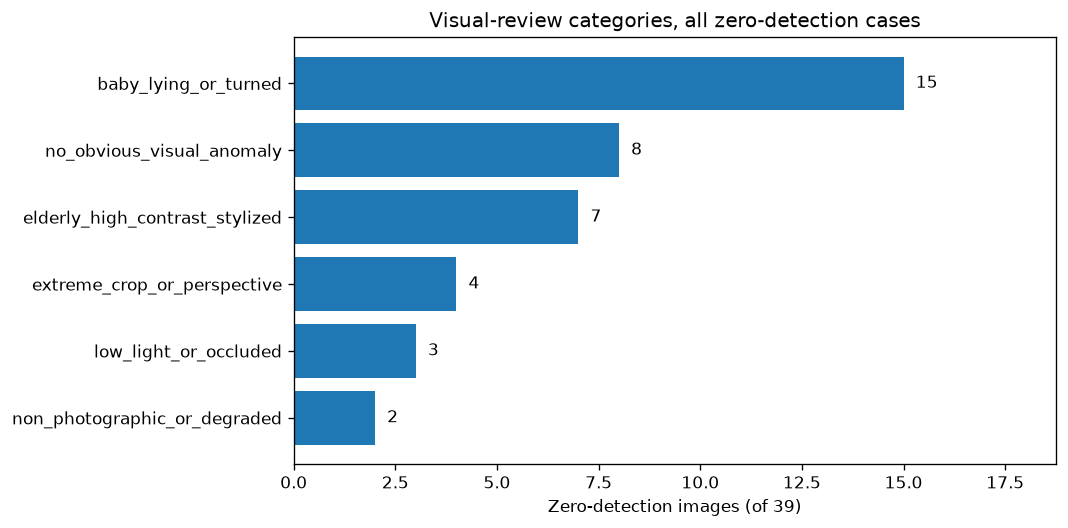

Visual review category counts:
visual_category
non_photographic_or_degraded       2
low_light_or_occluded              3
extreme_crop_or_perspective        4
elderly_high_contrast_stylized     7
no_obvious_visual_anomaly          8
baby_lying_or_turned              15


In [14]:
# Recorded by direct visual inspection of every image in the
# contact sheet above (not derived from any automated rule).
_visual_review = {
    "utkface-01ed50c1b4b9a290": ("baby_lying_or_turned", "Infant wrapped in towel, face turned roughly 45 degrees, stock-photo watermark visible."),
    "utkface-195ef2b18a77af08": ("elderly_high_contrast_stylized", "Frontal, but heavy grayscale/high-contrast artistic portrait with deep wrinkle texture."),
    "utkface-259de61d5d3372b4": ("elderly_high_contrast_stylized", "Frontal, black-and-white heavy-contrast artistic portrait, dark background."),
    "utkface-2d224e4b5c1a19f1": ("low_light_or_occluded", "Child's face mostly occluded by an adult's arm/body; only part of the face is visible."),
    "utkface-320416ebd0f63272": ("no_obvious_visual_anomaly", "Frontal, clear, well-lit close-up, mouth open."),
    "utkface-350f045a79de0140": ("baby_lying_or_turned", "Seated, face turned down at an angle, hair partly over face."),
    "utkface-453e42b79534e083": ("baby_lying_or_turned", "Lying on back, face turned to the side, mouth open."),
    "utkface-5384a0623ca792f4": ("extreme_crop_or_perspective", "Distant/small in frame at the beach, backlit, face angled down."),
    "utkface-54b9bfc82e461b49": ("no_obvious_visual_anomaly", "Adult male, frontal, clear, well lit, no occlusion apparent."),
    "utkface-64d8b281a352c19e": ("baby_lying_or_turned", "Lying on back, mouth open, small in frame, watermark text visible."),
    "utkface-653182ac4c4310af": ("extreme_crop_or_perspective", "Infant small in frame, supported by adult from behind, mostly frontal."),
    "utkface-6c19165a931ef14f": ("elderly_high_contrast_stylized", "Frontal, black-and-white heavy-contrast portrait, eyes squinting/closed."),
    "utkface-6dc14cd61d493c0e": ("baby_lying_or_turned", "Mid-motion dancing pose, face angled down, small and blurred, cutout-style image."),
    "utkface-6f72db672ea96a68": ("elderly_high_contrast_stylized", "Frontal, black-and-white heavy artistic texture."),
    "utkface-77c38f984e44d466": ("baby_lying_or_turned", "Outdoors, three-quarter angle, mid-stride, face turned."),
    "utkface-792915fe9f6b6544": ("extreme_crop_or_perspective", "Extremely tight crop; part of the face is cut off at the frame edge."),
    "utkface-7cbfe6c05172a8a3": ("no_obvious_visual_anomaly", "Elderly male, ID-style frontal photo, plain background, no apparent occlusion."),
    "utkface-7dcead6d8ada64fe": ("non_photographic_or_degraded", "Source image is a painting/artwork, not a photograph."),
    "utkface-809c76cfdcac9e41": ("baby_lying_or_turned", "Lying down, face turned to the side, mid-motion."),
    "utkface-8845e5991e711746": ("extreme_crop_or_perspective", "Extreme close-up with perspective distortion."),
    "utkface-8c685093672e2cd5": ("baby_lying_or_turned", "Seated, three-quarter angle, face turned away from camera."),
    "utkface-92a5366604c64969": ("no_obvious_visual_anomaly", "Newborn, frontal, eyes closed (sleeping), otherwise clear."),
    "utkface-943b7ccf7e869fed": ("baby_lying_or_turned", "Seated toddler, face angled down toward a toy."),
    "utkface-95831cb8664461d1": ("low_light_or_occluded", "Two infants overlapping in frame, top-down angle, faces small and close together."),
    "utkface-a340da2f7625bdc9": ("baby_lying_or_turned", "Lying on stomach, face turned to the side."),
    "utkface-aeae0861bb8099a0": ("no_obvious_visual_anomaly", "Infant close-up, frontal, clear lighting."),
    "utkface-aed9696ad25105a9": ("elderly_high_contrast_stylized", "Frontal but weathered skin and heavy beard texture, high local contrast."),
    "utkface-b136eb44acc1d169": ("low_light_or_occluded", "Dim indoor setting, face partially shadowed, small in frame."),
    "utkface-cff71fb66864c39d": ("no_obvious_visual_anomaly", "Toddler standing, mostly frontal, small in frame but clear."),
    "utkface-d42239680c83232d": ("baby_lying_or_turned", "Wrapped in towel/hood, frontal-ish, watermark text visible."),
    "utkface-d748ff7740f9488a": ("baby_lying_or_turned", "Outdoors, face turned to the side, mid-action."),
    "utkface-d8916a5624acb5a5": ("elderly_high_contrast_stylized", "Frontal, weathered/textured skin, heavy beard, high local contrast."),
    "utkface-e8d9de361235702d": ("elderly_high_contrast_stylized", "Stock photo, harsh directional side lighting, strong shadow across face, watermark visible."),
    "utkface-f5bfa36ddd7f791f": ("no_obvious_visual_anomaly", "Infant frontal, clear, mouth open."),
    "utkface-f9447f8e3b97e5a5": ("non_photographic_or_degraded", "Heavy halftone/dot-pattern texture across the image, degraded print/scan-like quality."),
    "utkface-fb5cfdd257e89928": ("no_obvious_visual_anomaly", "Infant close-up, frontal, clear lighting."),
    "utkface-fd2d34235e9f37d4": ("baby_lying_or_turned", "Standing toddler, mostly frontal, small figure, plain background."),
    "utkface-fd2fe2ec879a545e": ("baby_lying_or_turned", "Lying on side, face turned toward camera at an angle."),
    "utkface-ff04ee6ee7d91243": ("baby_lying_or_turned", "Lying on back, face turned to the side."),
}

missing_review = set(selected_failures["image_id"]) - set(_visual_review)
extra_review = set(_visual_review) - set(selected_failures["image_id"])

assert not missing_review, f"No visual review recorded for: {missing_review}"
assert not extra_review, f"Visual review recorded for non-failure images: {extra_review}"

review_table = selected_failures[[
    "image_id", "dataset", "original_path", "gender", "age_band", "race",
]].copy()

review_table["visual_category"] = review_table["image_id"].map(lambda i: _visual_review[i][0])
review_table["visual_review_note"] = review_table["image_id"].map(lambda i: _visual_review[i][1])

review_table = review_table.sort_values(
    ["visual_category", "image_id"], ignore_index=True
)

display(review_table)

category_counts = (
    review_table["visual_category"]
    .value_counts()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(category_counts.index, category_counts.to_numpy())

for i, value in enumerate(category_counts.to_numpy()):
    ax.text(value + 0.3, i, str(value), va="center")

ax.set_xlabel("Zero-detection images (of 39)")
ax.set_title("Visual-review categories, all zero-detection cases")
ax.set_xlim(0, category_counts.max() * 1.25)

fig.tight_layout()

fig.savefig(FIGURES / "visual_review_categories.png", bbox_inches="tight")
fig.savefig(FIGURES / "visual_review_categories.pdf", bbox_inches="tight")

plt.show()

print("Visual review category counts:")
print(category_counts.to_string())

In [15]:
tables = {
    "detection_integrity_by_dataset.csv": integrity_table,
    "detection_terminal_states.csv": terminal,
    "subgroup_detection_failures.csv": subgroup_failures,
    "subgroup_label_coverage.csv": label_coverage,
    "confidence_summary.csv": confidence_summary,
    "alignment_outcomes.csv": alignment_table,
    "alignment_failure_subgroups.csv": alignment_failures,
    "detection_provenance.csv": provenance,
}

for filename, table in tables.items():
    table.to_csv(
        OUTPUT / filename,
        index=False,
    )

confidence_values.to_parquet(
    OUTPUT / "confidence_values.parquet",
    index=False,
)

review_table.to_csv(
    OUTPUT / "failure_review.csv",
    index=False,
)


def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for block in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):
            digest.update(block)

    return digest.hexdigest()


git_result = subprocess.run(
    ["git", "rev-parse", "HEAD"],
    cwd=ROOT,
    capture_output=True,
    text=True,
    check=False,
)

git_revision = (
    git_result.stdout.strip()
    if git_result.returncode == 0
    else "unknown"
)

run_record = {
    "audit": "detector_stage_audit",
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "phase0_baseline_commit": "f072db1",
    "current_git_revision": git_revision,
    "random_seed": SEED,
    "detection_threshold": DETECTION_THRESHOLD,
    "phase0_master_content_hash": actual_master_hash,
    "inputs_sha256": {
        path.name: sha256_file(path)
        for path in [
            MASTER_PATH,
            MANIFEST_PATH,
            DIAGNOSTICS_PATH,
            REFERENCE_PATH,
        ]
    },
    "statistical_status": (
        "Descriptive analysis only; formal protocol "
        "tests and multiple-comparison decisions pending."
    ),
}

(OUTPUT / "audit_run_record.json").write_text(
    json.dumps(run_record, indent=2),
    encoding="utf-8",
)

print("Saved tables and figures:", OUTPUT)
print("Saved run record:", OUTPUT / "audit_run_record.json")
print()
print(
    "Draft report generation moved out of the notebook -- "
    "run run_generate_det005_report.py separately to (re)build "
    "docs/detector_stage_limitations_DRAFT.md from these "
    "saved outputs."
)

Saved tables and figures: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\detection_integrity
Saved run record: C:\Users\User1\projects\Algorithmic Fairness in Computer Vision\outputs\data_prep\detection_integrity\audit_run_record.json

Draft report generation moved out of the notebook -- run run_generate_det005_report.py separately to (re)build docs/detector_stage_limitations_DRAFT.md from these saved outputs.
